# Section 4.1: Exploratory Data Analysis (EDA) & Dataset Characterization
## Adaptive Smartphone UI Framework for Cross-Application Optimization

**Target Journal Venue:** High-Impact HCI / Mobile Computing Journal (IEEE THMS / ACM TiiS / Applied Soft Computing)

### Purpose of this Analysis:
Before training predictive machine learning models, rigorous exploratory data analysis is essential to:
1. **Characterize Biomechanical Properties:** Quantify central tendency, dispersion, skewness, and kurtosis of human motor interactions.
2. **Identify Physiological Outliers:** Detect sensor artifacts, uncharacteristically prolonged touch latencies, and extreme swipe velocity spikes.
3. **Investigate the Impact of Physical Locomotion:** Empirically demonstrate whether walking induces statistically significant touch degradation compared to sitting (justifying the need for real-time UI adaptation).
4. **Analyze Class Imbalance:** Examine distribution of target UI configurations (Small, Default, Large, Extra Large).
5. **Assess Multicollinearity:** Determine linear dependencies across touch features via Pearson correlation.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("EDA Environment Initialized.")

EDA Environment Initialized.


### 1. Ingest Unified Dataset & Basic Dimensions

In [2]:
train_path = os.path.join("processed", "final_ready_dataset.csv")
test_path  = os.path.join("processed", "bbmas_test_ready_dataset.csv")

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)
df_train["split"] = "Train (HMOG)"
df_test["split"]  = "Test (BB-MAS)"
df = pd.concat([df_train, df_test], ignore_index=True)

print(f"Train Set (HMOG) Loaded : {df_train.shape[0]} rows, {df_train['user_id'].nunique()} unique users.")
print(f"Test Set (BB-MAS) Loaded: {df_test.shape[0]} rows, {df_test['user_id'].nunique()} unique users.")
print(f"Total Combined Benchmark: {df.shape[0]} rows, {df['user_id'].nunique()} unique users.")
df.head(4)

Train Set (HMOG) Loaded : 7194 rows, 100 unique users.
Test Set (BB-MAS) Loaded: 4514 rows, 116 unique users.
Total Combined Benchmark: 11708 rows, 216 unique users.


,user_id,session_id,source_dataset,context_is_walking,touch_duration_mean_ms,swipe_speed_mean_pxps,swipe_distance_mean_px,typing_speed_kpm,backspace_rate,contact_size_mean,touch_x_mean,touch_y_mean,tap_accuracy,miss_rate,reaction_time_mean_ms,reaction_time_norm,target_button_size
0,hmog_100669,s_100669101000001,HMOG,0,525.44,800.0,250.0,180.0,0.08,0.0236,625.00,1042.44,0.92,0.08,330.0,0.2419,1
1,hmog_100669,s_100669102000001,HMOG,0,606.25,800.0,250.0,180.0,0.08,0.0227,547.42,959.67,0.92,0.08,330.0,0.2419,1
2,hmog_100669,s_100669103000001,HMOG,0,678.41,800.0,250.0,180.0,0.08,0.0230,602.48,918.56,0.92,0.08,330.0,0.2419,1
3,hmog_100669,s_100669104000001,HMOG,0,507.15,800.0,250.0,180.0,0.08,0.0231,624.67,926.81,0.92,0.08,330.0,0.2419,1


### 2. Comprehensive Biomechanical Summary Statistics (Table 1 for Paper)
We calculate the full parametric (Mean, Std Dev) and non-parametric (Median, IQR, Skewness, Kurtosis) summary across all human motor performance features.

In [3]:
features_to_analyze = [
    "touch_duration_mean_ms", "swipe_speed_mean_pxps", "swipe_distance_mean_px",
    "typing_speed_kpm", "backspace_rate", "contact_size_mean",
    "touch_x_mean", "touch_y_mean", "tap_accuracy", "miss_rate", "reaction_time_mean_ms"
]

summary_stats = []
for split_name, sub_df in [("Train (HMOG)", df_train), ("Test (BB-MAS)", df_test)]:
    for col in features_to_analyze:
        vals = sub_df[col].dropna()
        q25, q75 = vals.quantile(0.25), vals.quantile(0.75)
        dec = 4 if col == "contact_size_mean" else 2
        summary_stats.append({
            "Dataset": split_name,
            "Feature": col,
            "Mean": round(float(vals.mean()), dec),
            "Std Dev": round(float(vals.std()), dec),
            "Median": round(float(vals.median()), dec),
            "Q25": round(float(q25), dec),
            "Q75": round(float(q75), dec),
            "IQR": round(float(q75 - q25), dec),
            "Min": round(float(vals.min()), dec),
            "Max": round(float(vals.max()), dec),
            "Skewness": round(float(stats.skew(vals)), 2),
            "Kurtosis": round(float(stats.kurtosis(vals)), 2)
        })

stats_df = pd.DataFrame(summary_stats)
os.makedirs(os.path.join("paper_figures", "eda"), exist_ok=True)
stats_df.to_csv(os.path.join("paper_figures", "eda", "eda_summary_statistics_table.csv"), index=False)
stats_df

,Dataset,Feature,Mean,Std Dev,Median,Q25,Q75,IQR,Min,Max,Skewness,Kurtosis
0,Train (HMOG),touch_duration_mean_ms,445.2100,336.1300,455.9800,112.0000,638.8500,526.8500,16.0000,2656.2000,1.11,2.48
1,Train (HMOG),swipe_speed_mean_pxps,851.4900,563.8300,800.0000,497.3900,967.3200,469.9300,61.4800,14372.5300,4.14,55.64
2,Train (HMOG),swipe_distance_mean_px,311.3600,191.2600,302.0000,213.3100,451.5600,238.2500,7.4700,1441.5300,0.19,-0.22
3,Train (HMOG),typing_speed_kpm,183.9000,34.1600,180.0000,180.0000,180.0000,0.0000,55.1000,400.0000,1.26,5.16
4,Train (HMOG),backspace_rate,0.0900,0.0300,0.0800,0.0800,0.0800,0.0000,0.0000,0.3000,2.23,6.88
5,Train (HMOG),contact_size_mean,0.0250,0.0022,0.0247,0.0235,0.0262,0.0027,0.0175,0.0363,0.77,0.97
6,Train (HMOG),touch_x_mean,634.4500,186.3500,616.0900,549.5800,685.0400,135.4700,49.0000,1604.6700,1.47,5.15
7,Train (HMOG),touch_y_mean,738.2200,322.1200,852.7300,445.5100,987.5200,542.0100,12.0000,1458.0000,-0.58,-0.98
8,Train (HMOG),tap_accuracy,0.9100,0.0300,0.9200,0.9200,0.9200,0.0000,0.7000,0.9800,-2.26,6.92
9,Train (HMOG),miss_rate,0.0900,0.0300,0.0800,0.0800,0.0800,0.0000,0.0200,0.3000,2.26,6.92


### 3. Figure 1: Biomechanical Feature Distributions (KDE & Histograms)
Visualizing continuous distributions to identify skewness and normality across motor metrics.

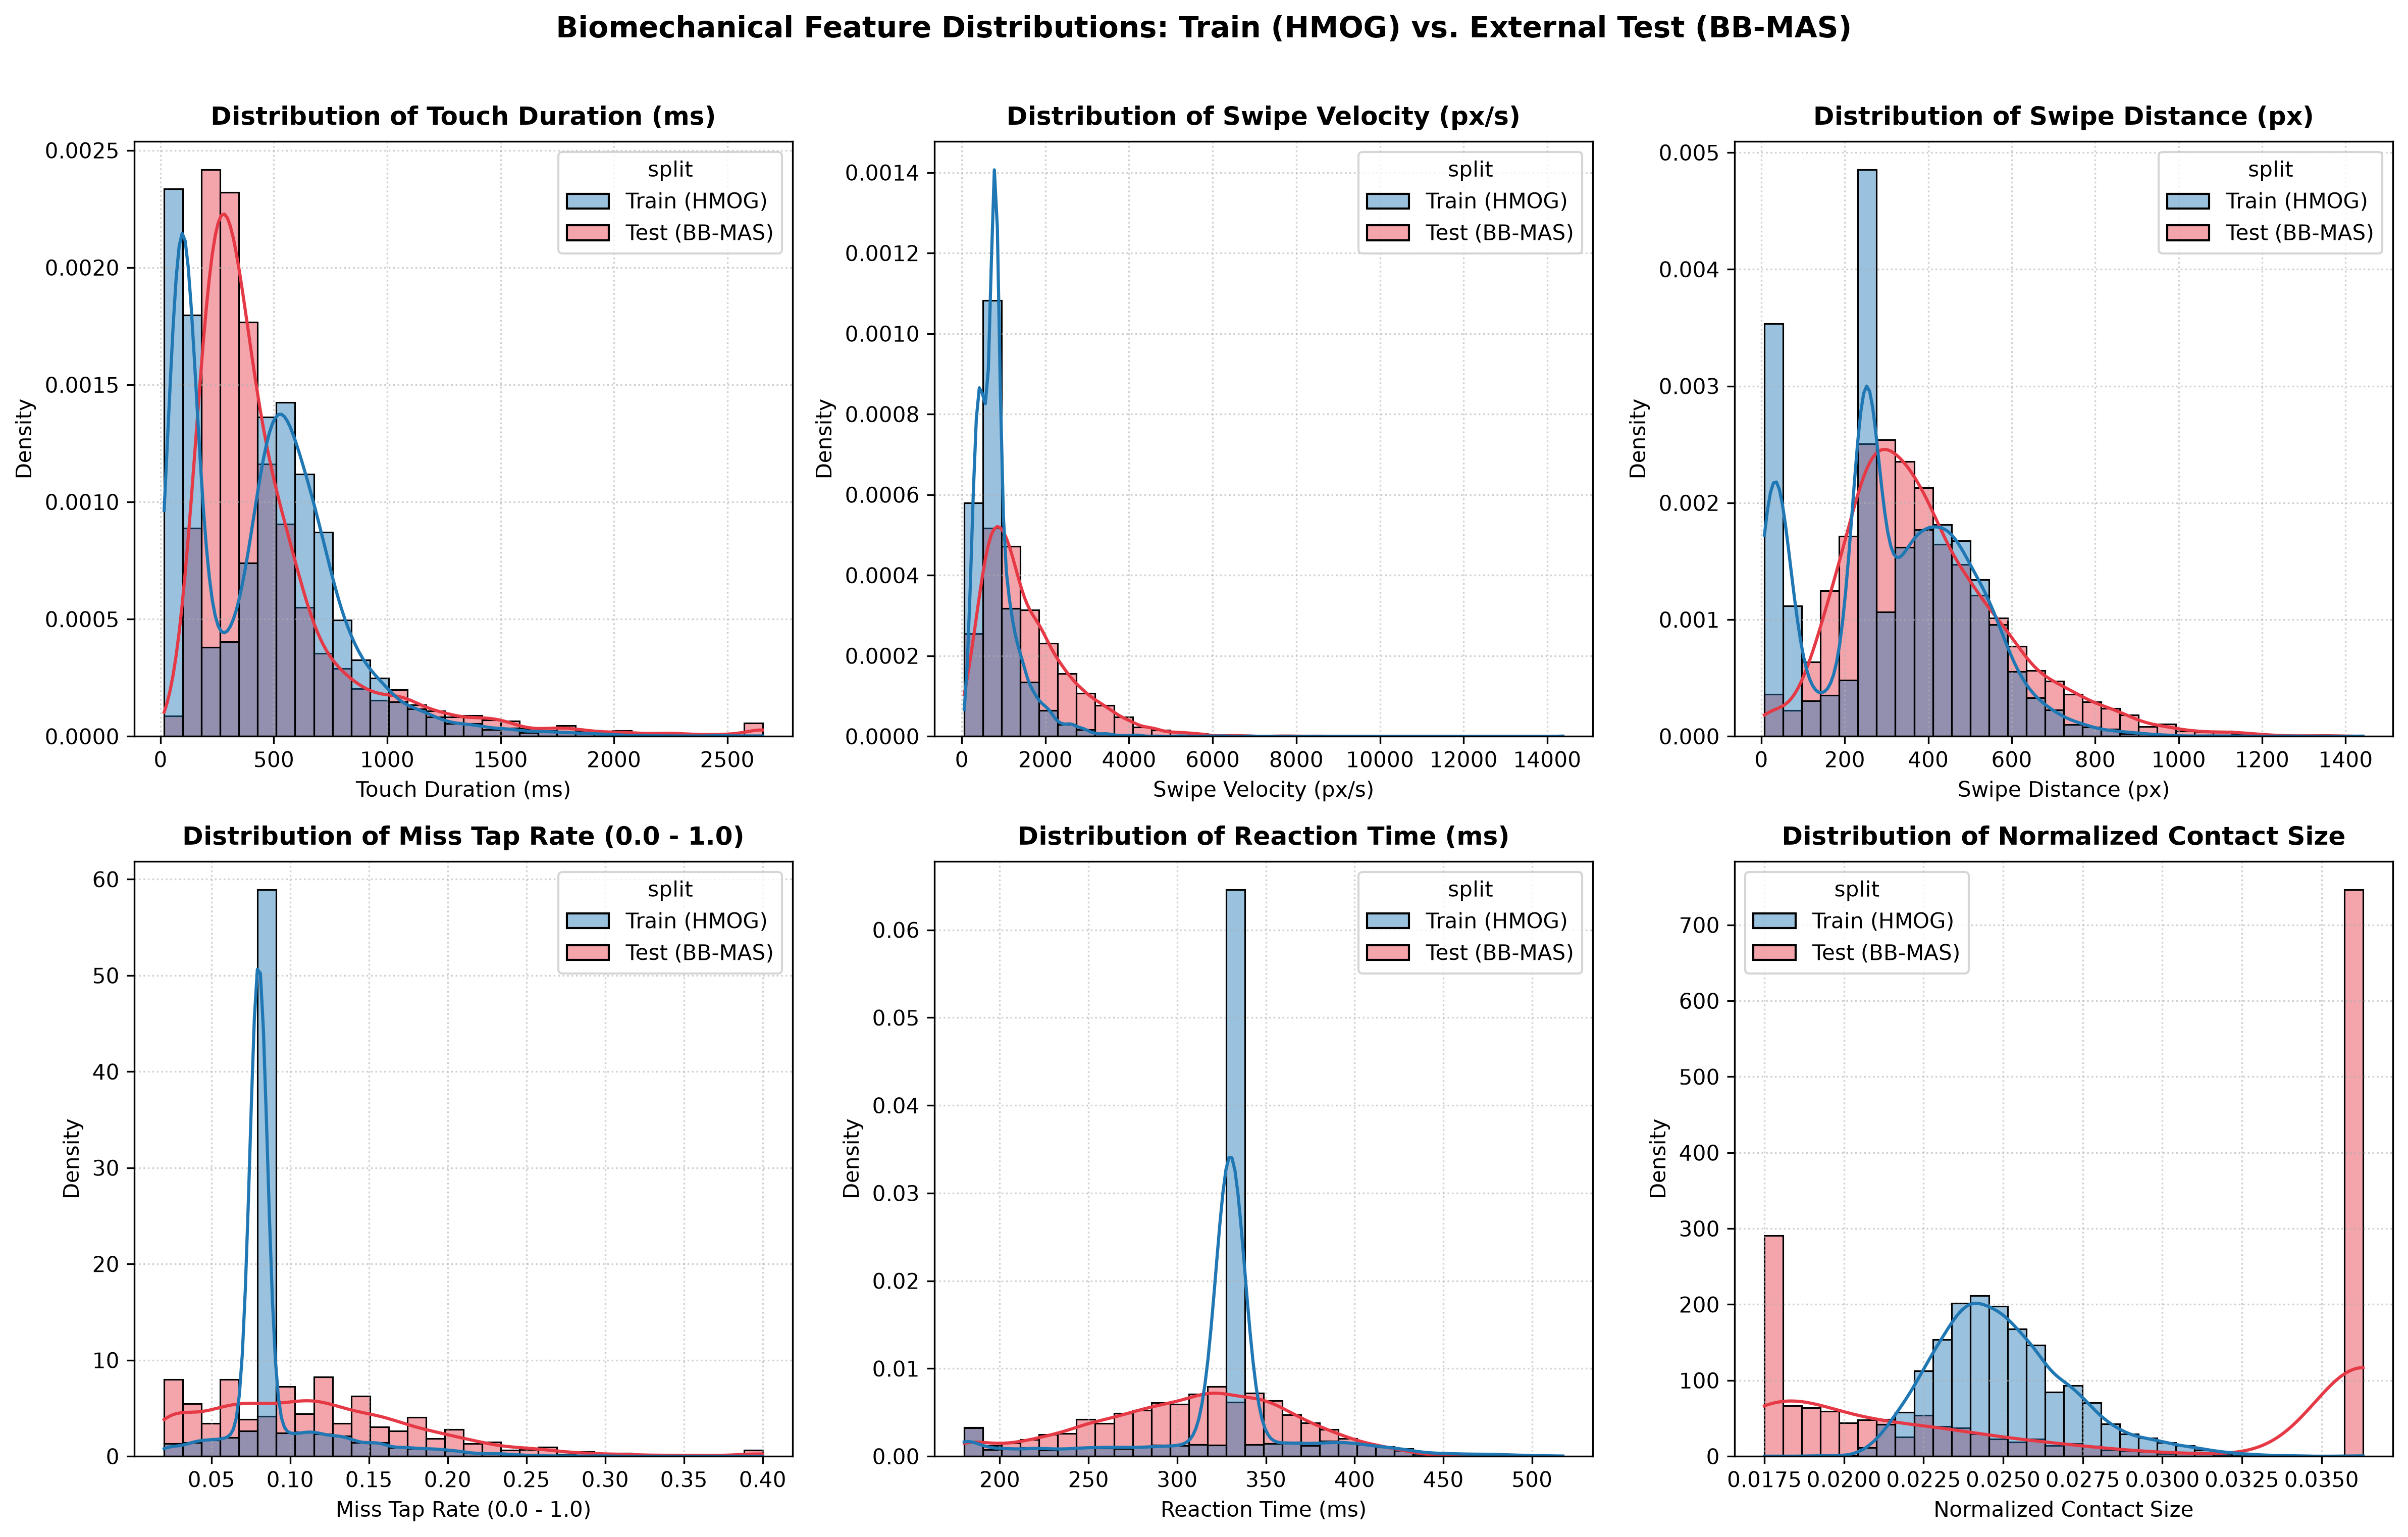

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
plot_feats = [
    ("touch_duration_mean_ms", "Touch Duration (ms)", 0, 0),
    ("swipe_speed_mean_pxps", "Swipe Velocity (px/s)", 0, 1),
    ("swipe_distance_mean_px", "Swipe Distance (px)", 0, 2),
    ("miss_rate", "Miss Tap Rate (0.0 - 1.0)", 1, 0),
    ("reaction_time_mean_ms", "Reaction Time (ms)", 1, 1),
    ("contact_size_mean", "Normalized Contact Size", 1, 2),
]

for idx, (col, label, r, c) in enumerate(plot_feats):
    ax = axes[r, c]
    sns.histplot(
        data=df, x=col, hue="split", kde=True, stat="density", common_norm=False,
        palette={"Train (HMOG)": "#1f77b4", "Test (BB-MAS)": "#e63946"},
        bins=32, alpha=0.45, ax=ax
    )
    ax.set_title(f"Distribution of {label}", fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Biomechanical Feature Distributions: Train (HMOG) vs. External Test (BB-MAS)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join("paper_figures", "eda", "fig1_feature_distributions.png"), dpi=300, bbox_inches="tight")
plt.show()

### 4. Figure 2: Outlier Dispersion & Sensor Noise Analysis
Touch devices capture involuntary tremors, capacitive jitter, and resting palm touch events. Boxplots demonstrate the spread and bounds required for normalization.

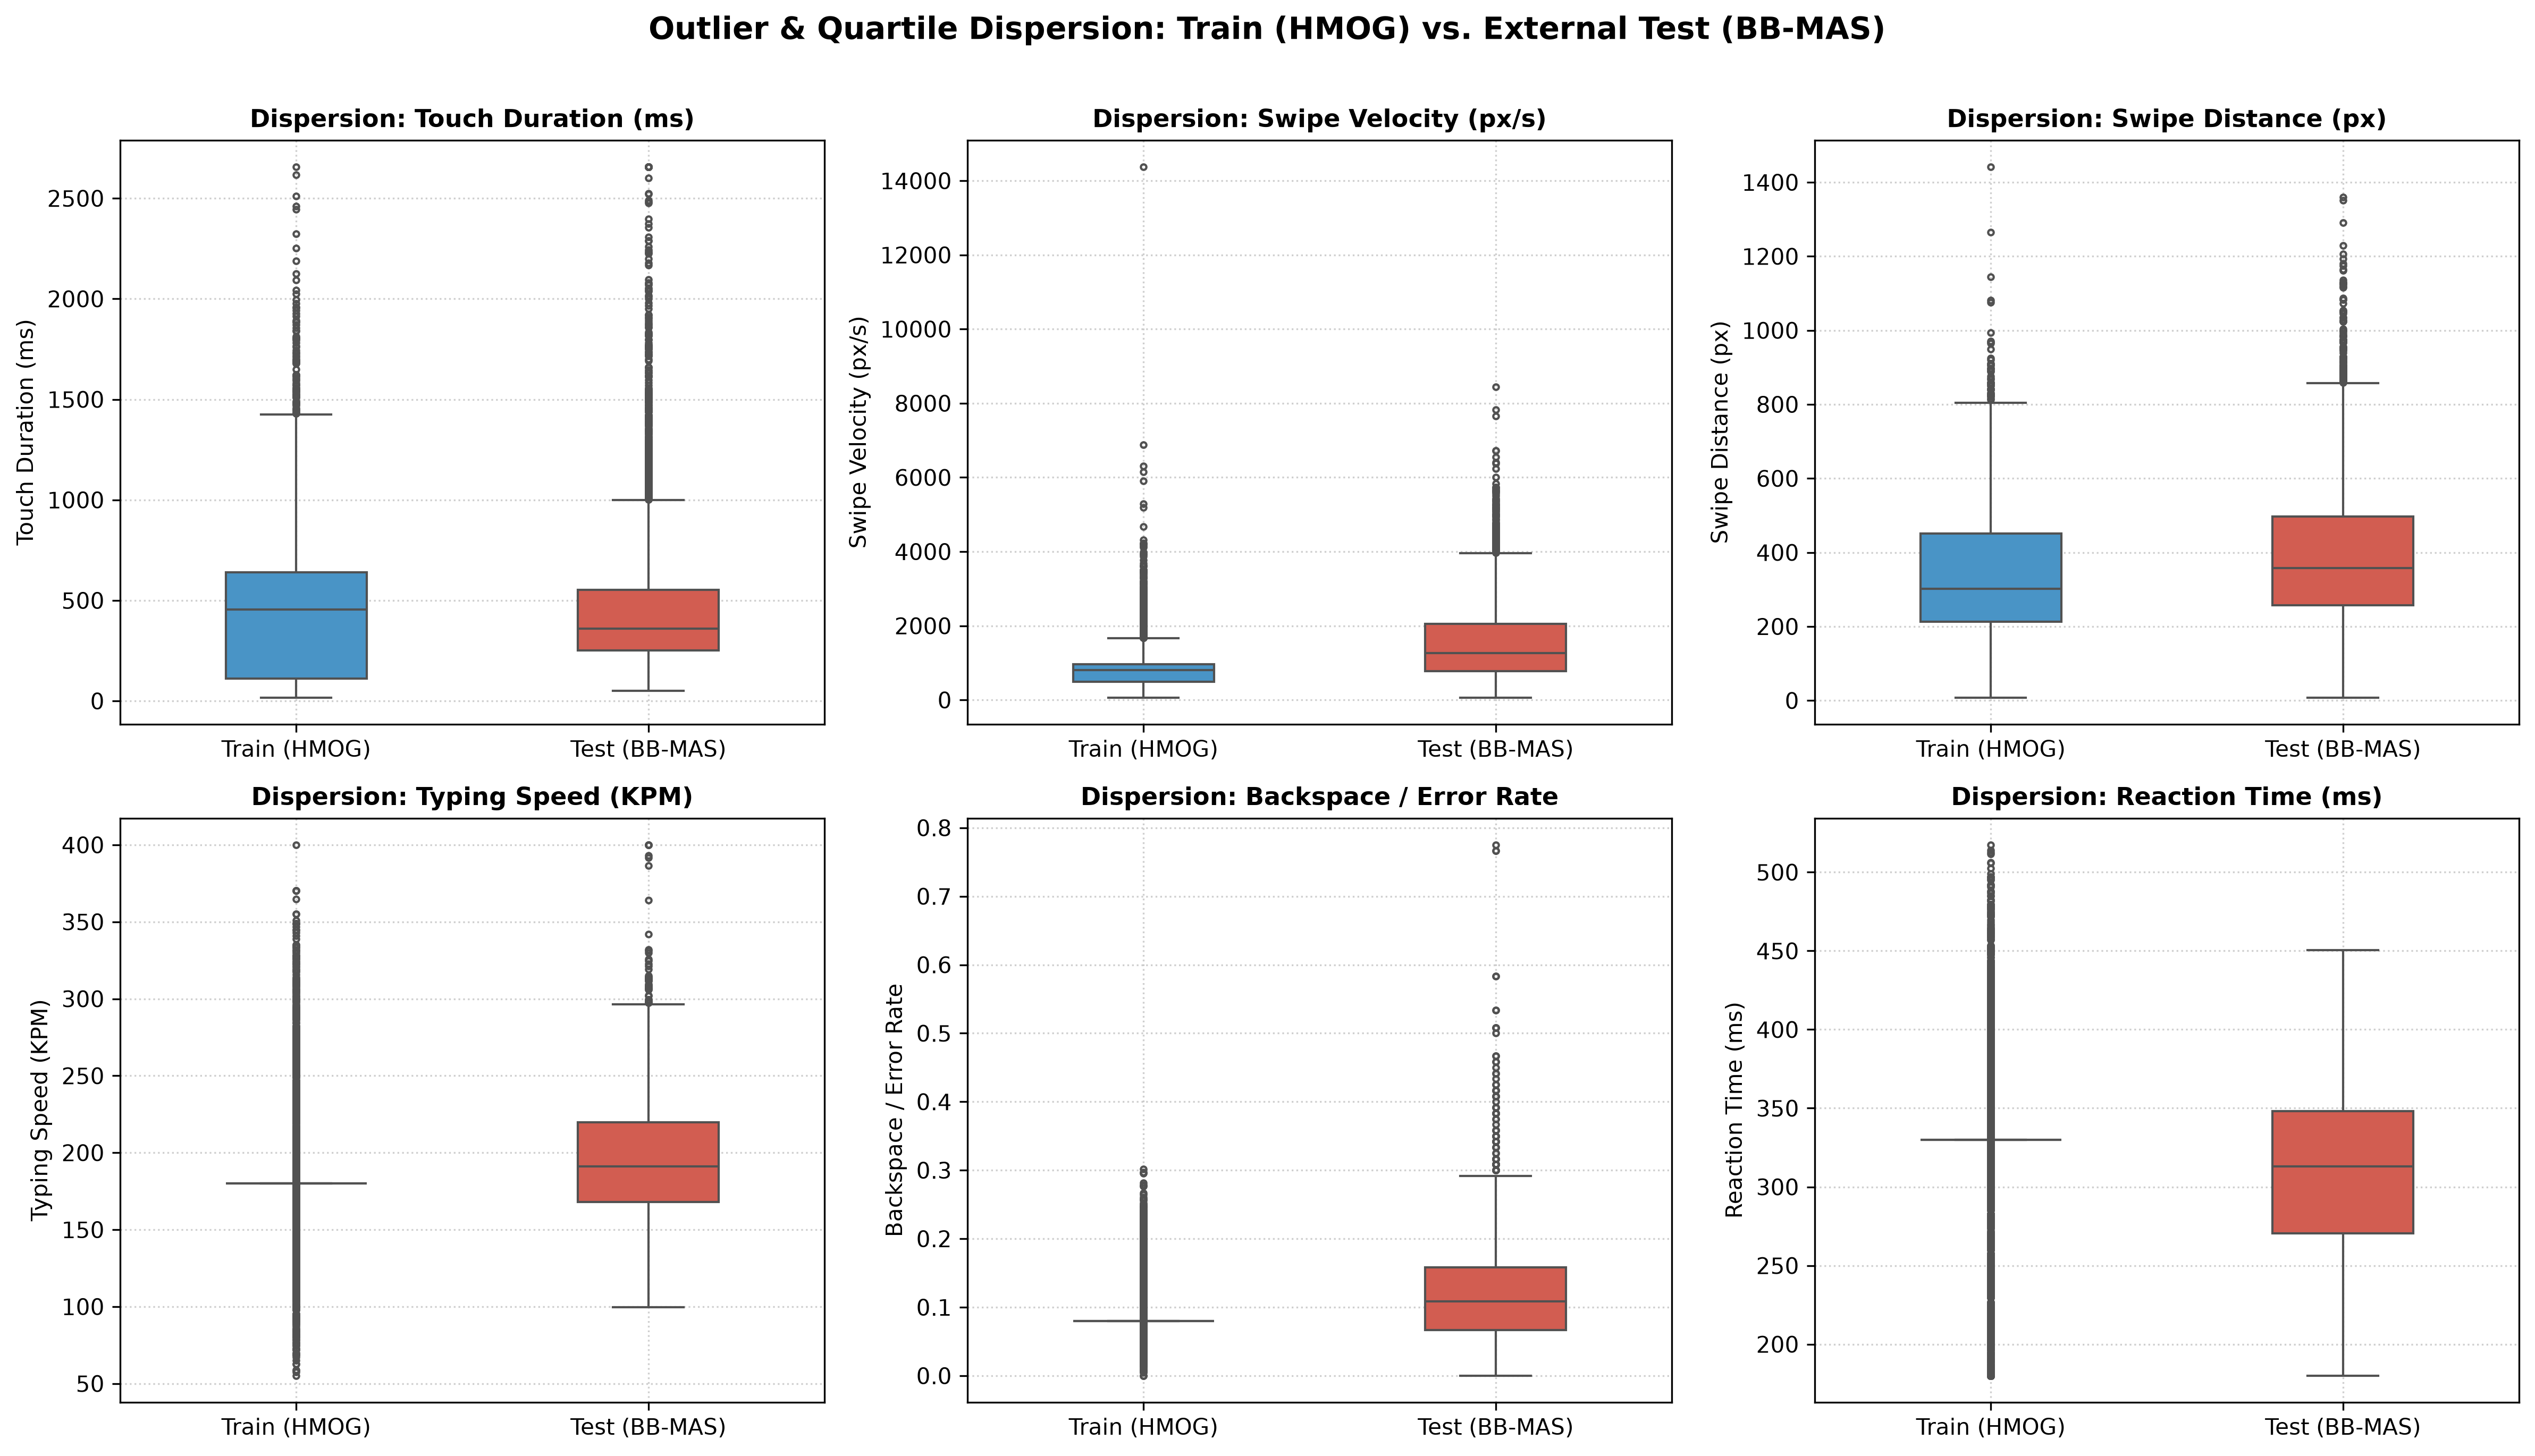

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
box_cols = [
    ("touch_duration_mean_ms", "Touch Duration (ms)", 0, 0),
    ("swipe_speed_mean_pxps", "Swipe Velocity (px/s)", 0, 1),
    ("swipe_distance_mean_px", "Swipe Distance (px)", 0, 2),
    ("typing_speed_kpm", "Typing Speed (KPM)", 1, 0),
    ("backspace_rate", "Backspace / Error Rate", 1, 1),
    ("reaction_time_mean_ms", "Reaction Time (ms)", 1, 2),
]

for col, label, r, c in box_cols:
    ax = axes[r, c]
    sns.boxplot(
        data=df, x="split", y=col, hue="split", legend=False, ax=ax,
        palette={"Train (HMOG)": "#3498db", "Test (BB-MAS)": "#e74c3c"},
        width=0.4, fliersize=2.5
    )
    ax.set_title(f"Dispersion: {label}", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label, fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Outlier & Quartile Dispersion: Train (HMOG) vs. External Test (BB-MAS)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join("paper_figures", "eda", "fig2_outlier_boxplots.png"), dpi=300, bbox_inches="tight")
plt.show()

### 5. Figure 3: Physical Locomotion Impact (Sitting vs. Walking Context)
**Core Research Question:** Does walking introduce statistically significant motor degradation in smartphone interactions?
We conduct a formal **Welch's Two-Sample t-test** to compare miss tap rates and reaction times across stationary (sitting) and mobile (walking) conditions.

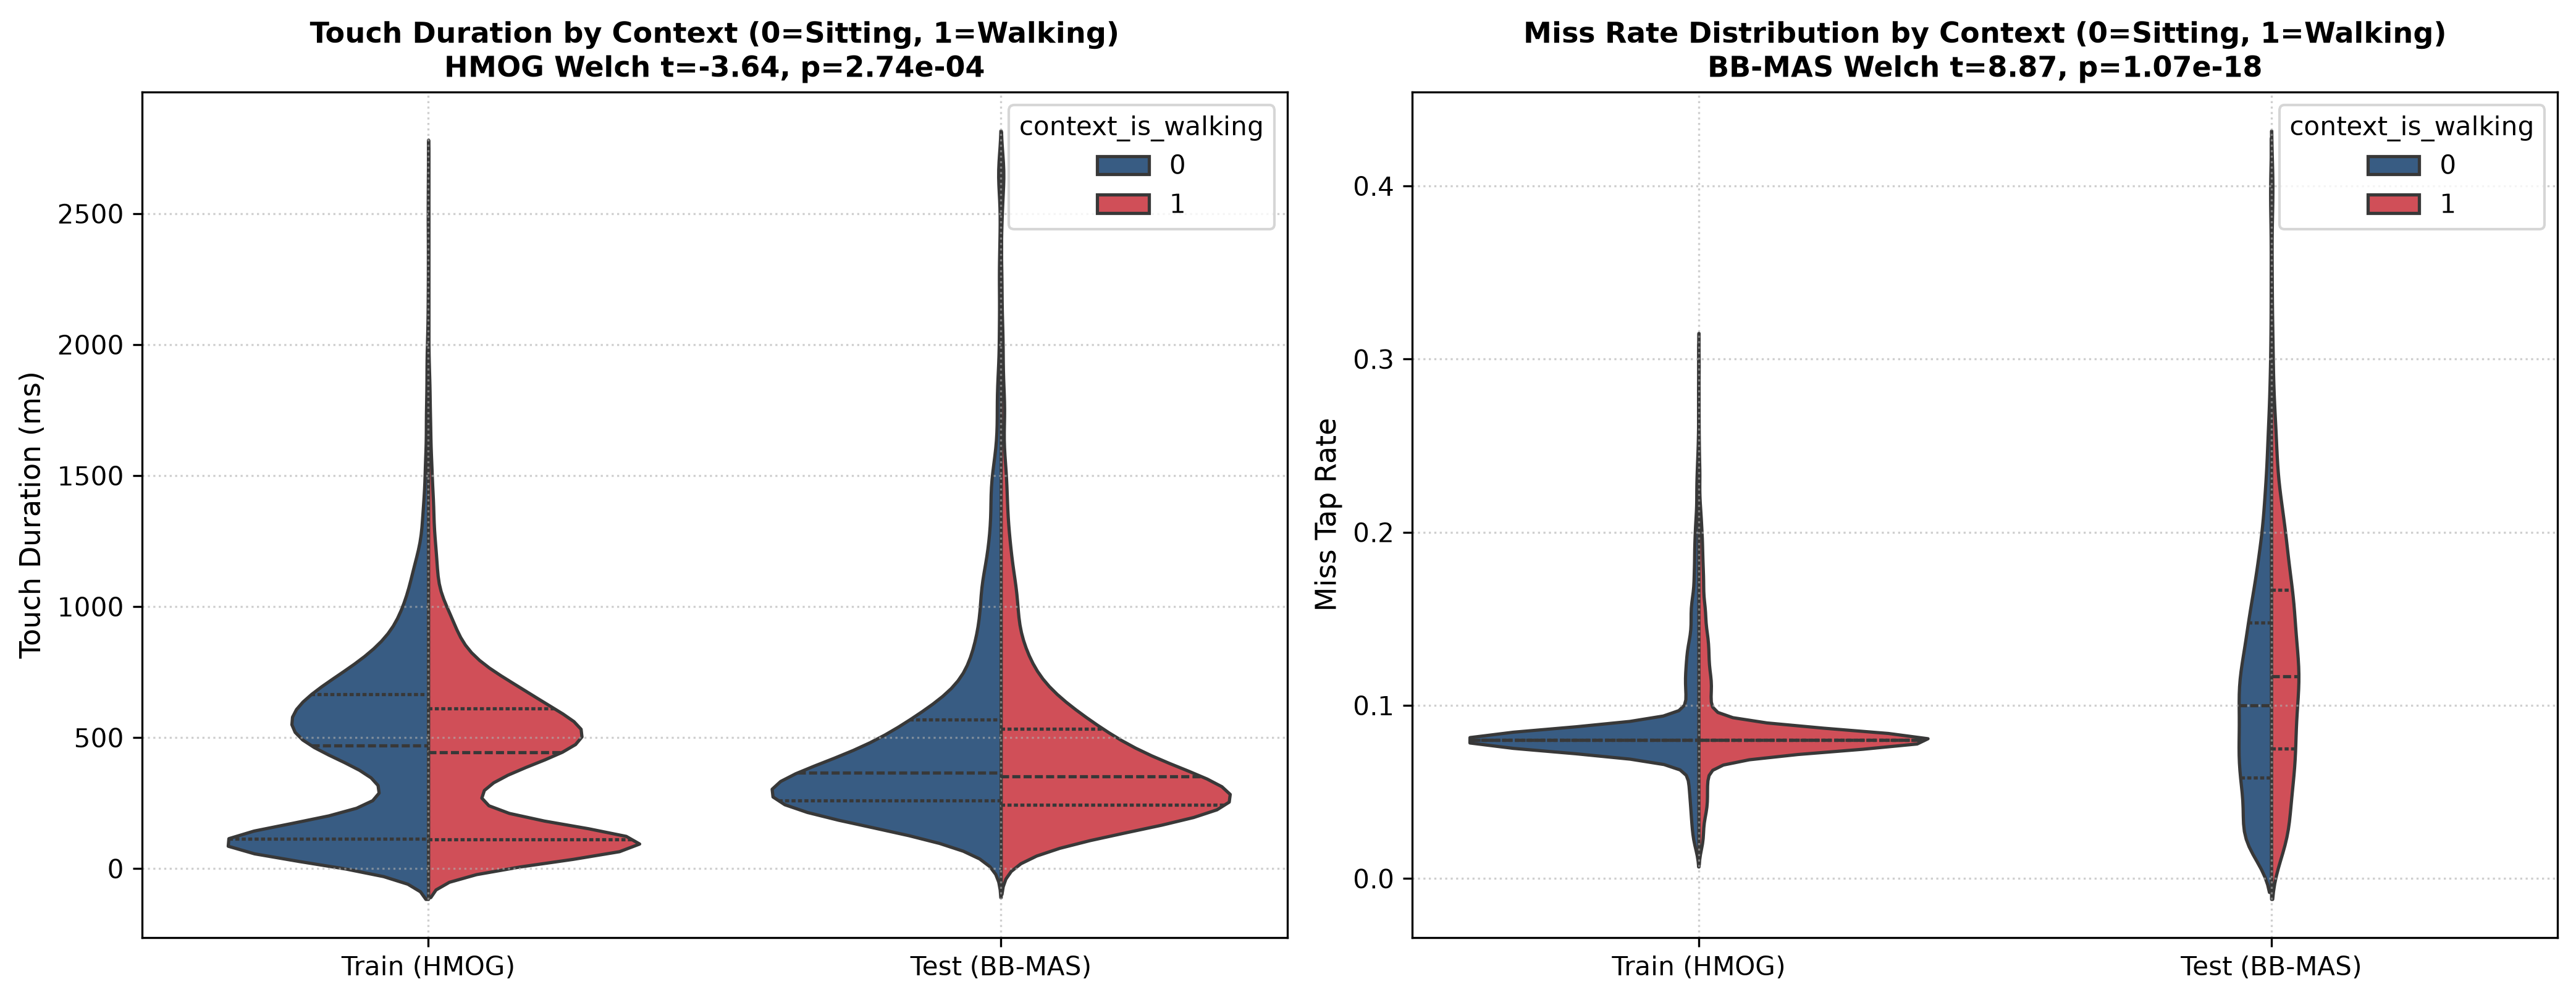

In [6]:
sit_train  = df_train[df_train["context_is_walking"] == 0]["touch_duration_mean_ms"]
walk_train = df_train[df_train["context_is_walking"] == 1]["touch_duration_mean_ms"]
t_tr, p_tr = stats.ttest_ind(walk_train, sit_train, equal_var=False)

sit_test  = df_test[df_test["context_is_walking"] == 0]["miss_rate"]
walk_test = df_test[df_test["context_is_walking"] == 1]["miss_rate"]
t_te, p_te = stats.ttest_ind(walk_test, sit_test, equal_var=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.violinplot(
    data=df, x="split", y="touch_duration_mean_ms", hue="context_is_walking",
    split=True, inner="quartile", palette={0: "#2b5c8f", 1: "#e63946"}, ax=axes[0]
)
axes[0].set_title(f"Touch Duration by Context (0=Sitting, 1=Walking)\nHMOG Welch t={t_tr:.2f}, p={p_tr:.2e}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Touch Duration (ms)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)

sns.violinplot(
    data=df, x="split", y="miss_rate", hue="context_is_walking",
    split=True, inner="quartile", palette={0: "#2b5c8f", 1: "#e63946"}, ax=axes[1]
)
axes[1].set_title(f"Miss Rate Distribution by Context (0=Sitting, 1=Walking)\nBB-MAS Welch t={t_te:.2f}, p={p_te:.2e}", fontsize=11, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Miss Tap Rate", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join("paper_figures", "eda", "fig3_context_impact_sitting_vs_walking.png"), dpi=300, bbox_inches="tight")
plt.show()

### 6. Figure 4: Target Adaptation Class Balance & Distribution

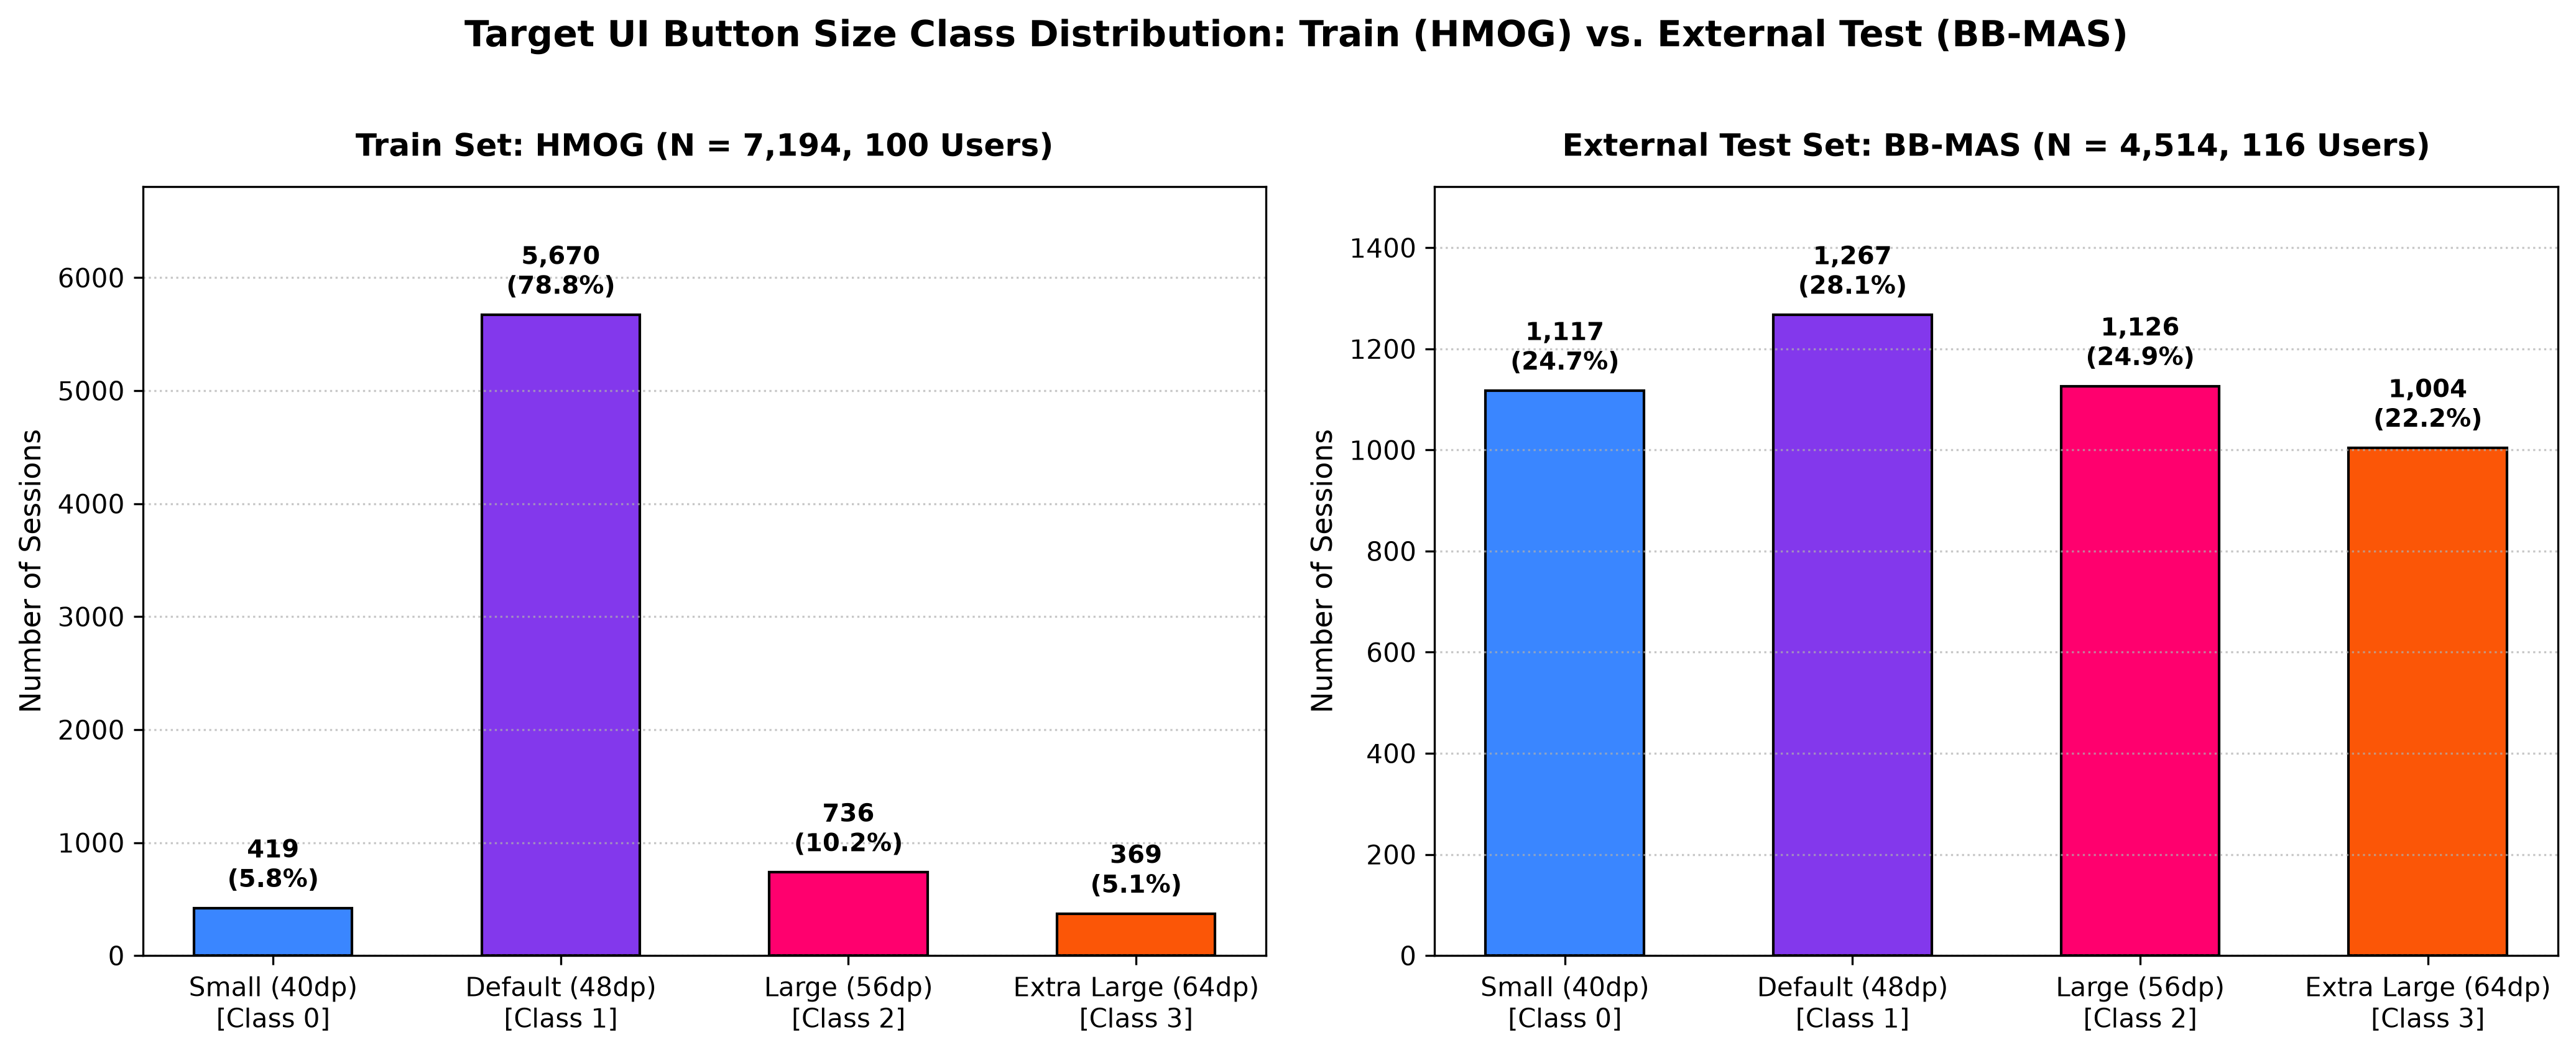

In [7]:
labels = ["Small (40dp)\n[Class 0]", "Default (48dp)\n[Class 1]", "Large (56dp)\n[Class 2]", "Extra Large (64dp)\n[Class 3]"]
colors = ["#3a86ff", "#8338ec", "#ff006e", "#fb5607"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, sub_df) in zip(axes, [
    ("Train Set: HMOG (N = 7,194, 100 Users)", df_train),
    ("External Test Set: BB-MAS (N = 4,514, 116 Users)", df_test),
]):
    counts = [int((sub_df["target_button_size"] == i).sum()) for i in range(4)]
    bars = ax.bar(labels, counts, color=colors, edgecolor="black", width=0.55)
    for bar in bars:
        yv = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            yv + max(counts) * 0.02,
            f"{yv:,}\n({yv/len(sub_df)*100:.1f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Number of Sessions", fontsize=11)
    ax.set_ylim(0, max(counts) * 1.20)
    ax.grid(axis="y", linestyle=":", alpha=0.7)

plt.suptitle("Target UI Button Size Class Distribution: Train (HMOG) vs. External Test (BB-MAS)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join("paper_figures", "eda", "fig4_class_distribution_balance.png"), dpi=300, bbox_inches="tight")
plt.show()

### 7. Figure 5: Feature Multicollinearity & Pearson Correlation Matrix

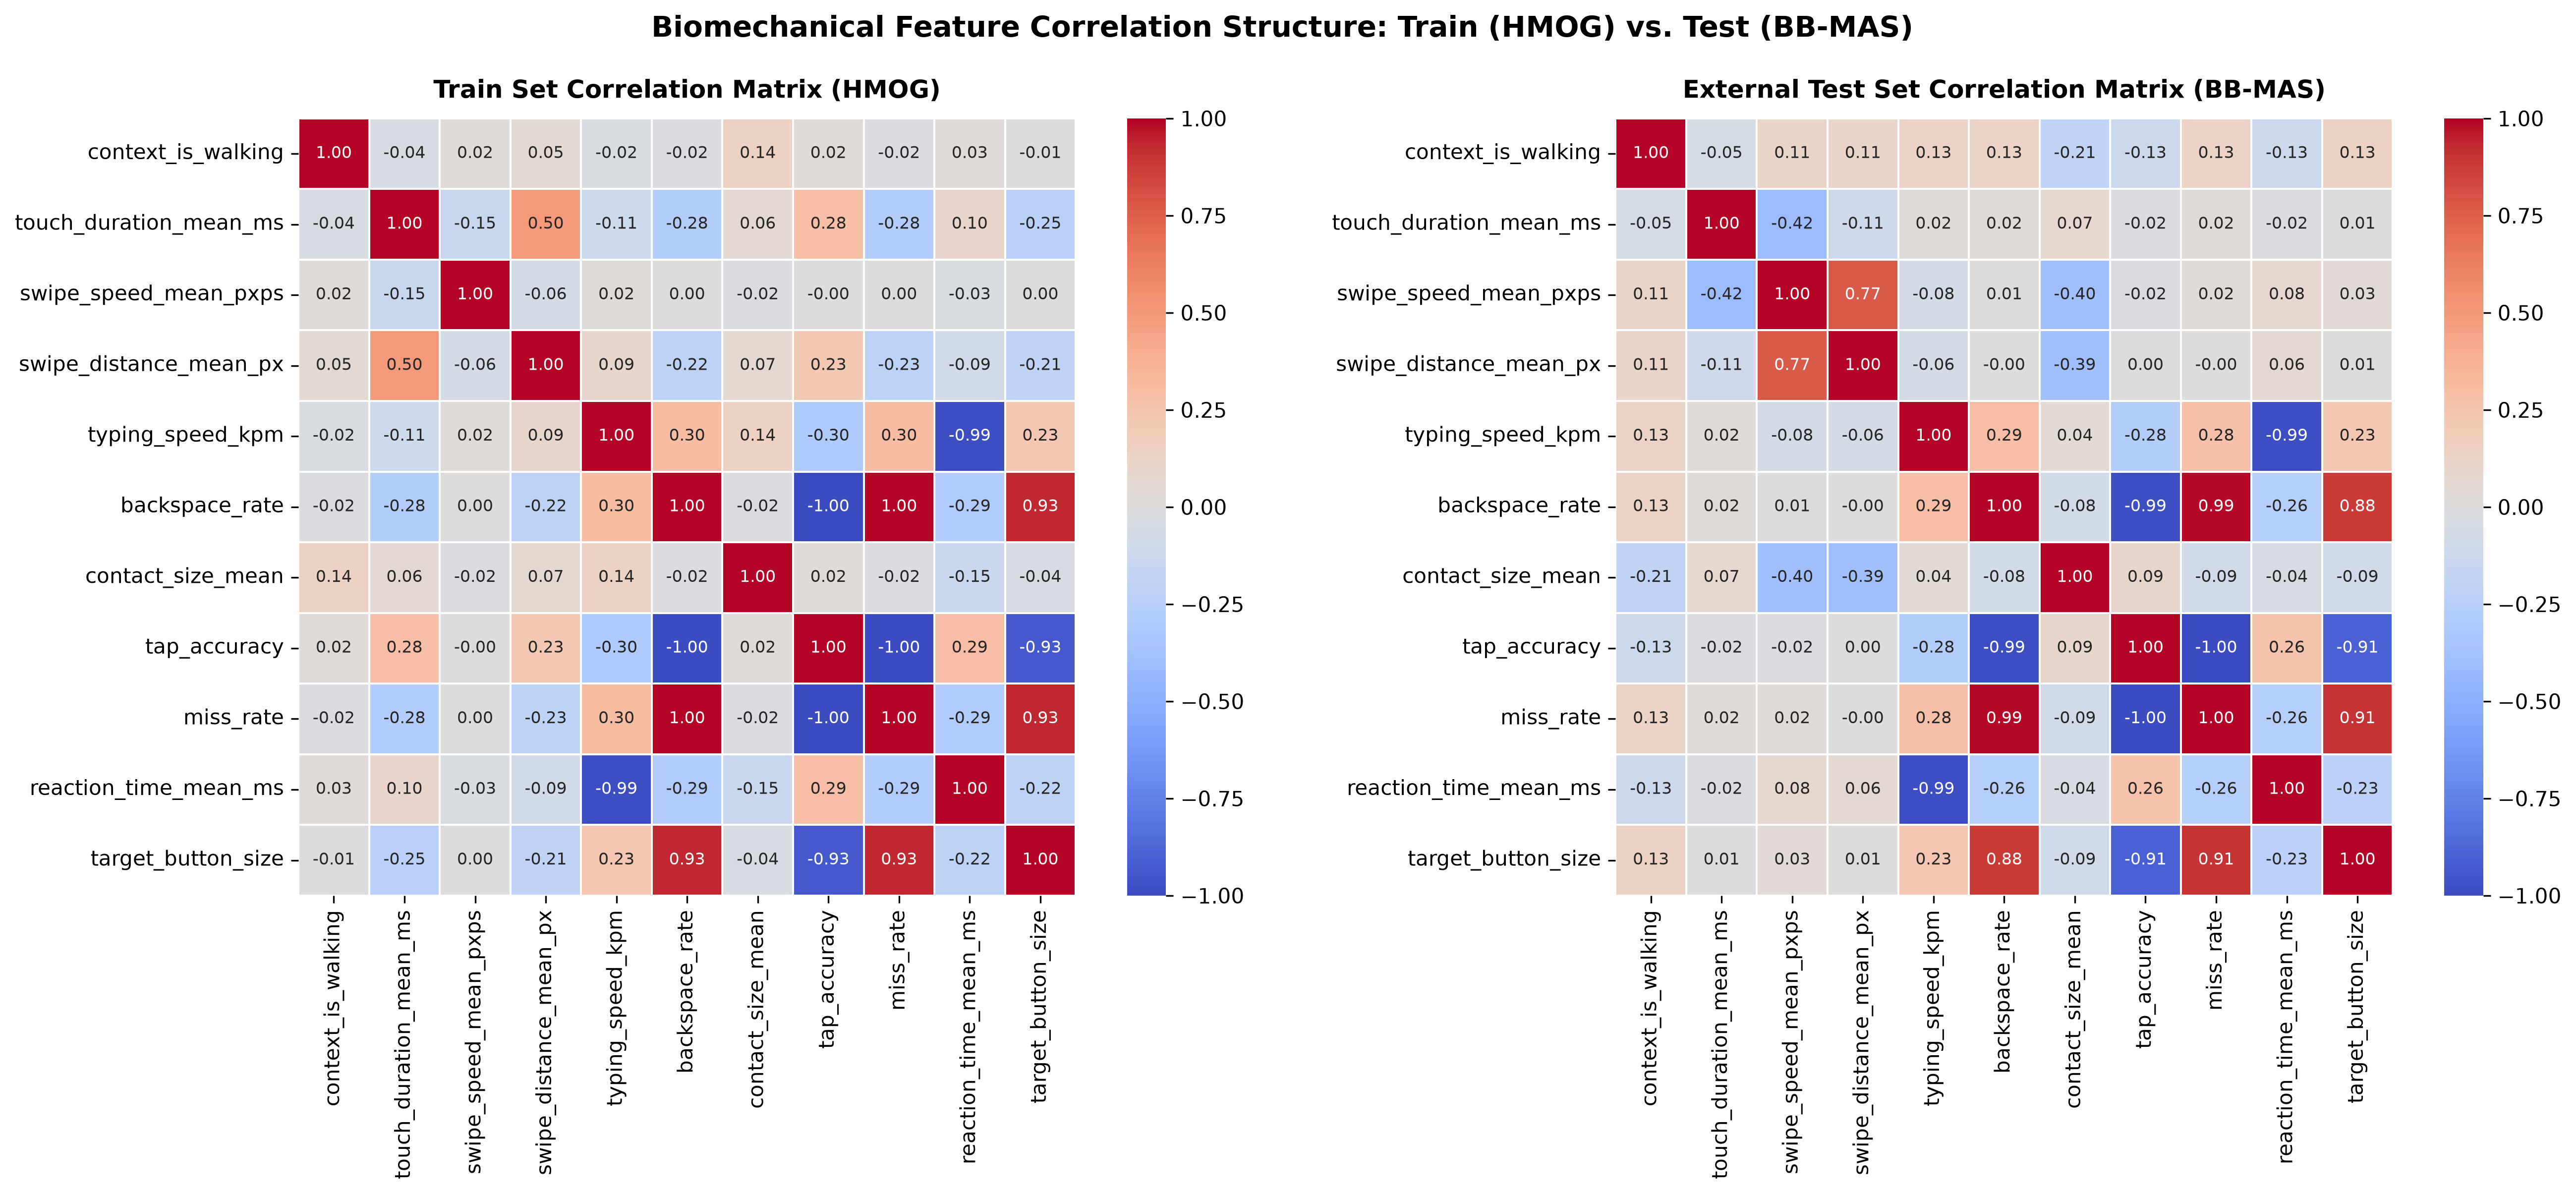

In [8]:
corr_cols = [
    "context_is_walking", "touch_duration_mean_ms", "swipe_speed_mean_pxps",
    "swipe_distance_mean_px", "typing_speed_kpm", "backspace_rate",
    "contact_size_mean", "tap_accuracy", "miss_rate",
    "reaction_time_mean_ms", "target_button_size",
]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (title, sub_df) in zip(axes, [
    ("Train Set Correlation Matrix (HMOG)", df_train),
    ("External Test Set Correlation Matrix (BB-MAS)", df_test),
]):
    cmat = sub_df[corr_cols].corr()
    sns.heatmap(
        cmat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
        square=True, linewidths=0.5, ax=ax, annot_kws={"size": 8}
    )
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)

plt.suptitle("Biomechanical Feature Correlation Structure: Train (HMOG) vs. Test (BB-MAS)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join("paper_figures", "eda", "fig5_feature_correlation_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()